# ۲ — آمار توصیفی، هیستوگرام، منحنی نرمال و قانون 68–95–99.7

این نوت‌بوک با فایل `outputs/numeric_features.csv` حاصل از نوت‌بوک شماره ۱ کار می‌کند.

موارد موردنظر استاد: Range، Mean، Median، Q1/Q2/Q3/Q4، هیستوگرام، مقایسه منحنی تجربی با نرمال و نمایش/مقایسه درصدها در بازه‌های ±۱، ±۲ و ±۳ انحراف معیار.

**توضیح علمی:** Q1، Q2 و Q3 مرز چارک‌ها هستند و Q4 معمولاً **بازه چهارم از Q3 تا Max** است. در جدول ستون Q4_upper (صدک ۱۰۰/Max) نیز برای کامل بودن می‌آید. نسبت‌های 68.27٪، 95.45٪، 99.73٪ ویژه توزیع نرمال‌اند؛ ممکن است داده‌های شمارشی/گسسته تبعیت نکنند.

> اسلاید ۳۹ در فایل پروپوزال وجود ندارد؛ اینجا **با فرض اینکه منظور قانون تجربی 68–95–99.7 است** آن را پیاده کرده‌ایم.

In [1]:
# Setup for Google Colab (runs automatically if inside Colab)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    if not Path('/content/drive').exists():
        drive.mount('/content/drive')
        print("Google Drive mounted at /content/drive")


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm
from IPython.display import display

# Automatic project root detection (works in local project root, notebooks directory, or Google Colab)
def find_project_root():
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path('/content/drive/MyDrive/project'),
        Path('/content/drive/MyDrive/Detecting Silent Failures of Uncertainty Estimators'),
        Path('/content/drive/MyDrive'),
        Path('/content'),
    ]
    for cand in candidates:
        if (cand / 'outputs' / 'numeric_features.csv').exists():
            return cand
    for cand in candidates:
        if (cand / 'datasets' / 'commonsense_qa').exists():
            return cand
    return Path.cwd()

ROOT = find_project_root()
OUTPUT = ROOT / 'outputs'
CHARTS = OUTPUT / 'charts'
CHARTS.mkdir(parents=True, exist_ok=True)
path = OUTPUT / 'numeric_features.csv'
if not path.exists():
    raise FileNotFoundError('First run 01_prepare_numeric_features.ipynb (numeric_features.csv missing)')
data = pd.read_csv(path)
FEATURES = ['question_words', 'question_chars', 'avg_option_words', 'option_count']
missing = set(['dataset', 'split', *FEATURES]) - set(data.columns)
if missing:
    raise ValueError(f'Missing columns in numeric_features.csv: {missing}')
print(f'Project ROOT: {ROOT}')
print('Loaded', len(data), 'rows')
display(data.groupby(['dataset', 'split']).size().rename('samples').to_frame())


Project ROOT: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators
Loaded 14692 rows


samples
dataset       split              
ARC-Challenge test           1172
              train          1119
              validation      299
CommonsenseQA test           1140
              train          9741
              validation     1221

## ۱. جدول Range, Mean, Median, Q1 تا Q4، انحراف معیار

In [3]:
def stats(values):
    x=pd.to_numeric(pd.Series(values),errors='coerce').dropna().to_numpy(dtype=float)
    if len(x)==0:
        return {k:np.nan for k in ['N','Min','Max','Range','Mean','Median','Q1','Q2','Q3','Q4_upper','Std_population']}
    q1,q2,q3,q4=np.percentile(x,[25,50,75,100])
    return {'N':len(x),'Min':x.min(),'Max':x.max(),'Range':x.max()-x.min(),
            'Mean':x.mean(),'Median':np.median(x),
            'Q1':q1,'Q2':q2,'Q3':q3,'Q4_upper':q4,
            'Std_population':x.std(ddof=0)}

all_rows=[]
split_rows=[]
quartile_intervals=[]
for name,group in data.groupby('dataset',sort=False):
    for feat in FEATURES:
        s=stats(group[feat]); all_rows.append({'dataset':name,'feature':feat,**s})
        quartile_intervals.append({'dataset':name,'feature':feat,
             'Quartile_1':f"{s['Min']:.2f} to {s['Q1']:.2f}",
             'Quartile_2':f"{s['Q1']:.2f} to {s['Q2']:.2f}",
             'Quartile_3':f"{s['Q2']:.2f} to {s['Q3']:.2f}",
             'Quartile_4':f"{s['Q3']:.2f} to {s['Q4_upper']:.2f}"})
for (name,split),group in data.groupby(['dataset','split'],sort=False):
    for feat in FEATURES:
        split_rows.append({'dataset':name,'split':split,'feature':feat,**stats(group[feat])})
summary=pd.DataFrame(all_rows)
by_split=pd.DataFrame(split_rows)
quartiles=pd.DataFrame(quartile_intervals)
display(summary.round(3))
display(quartiles)
summary.to_csv(OUTPUT/'descriptive_statistics.csv',index=False,encoding='utf-8-sig')
by_split.to_csv(OUTPUT/'descriptive_statistics_by_split.csv',index=False,encoding='utf-8-sig')
quartiles.to_csv(OUTPUT/'quartile_intervals.csv',index=False,encoding='utf-8-sig')

,dataset,feature,N,Min,Max,Range,Mean,Median,Q1,Q2,Q3,Q4_upper,Std_population
0,CommonsenseQA,question_words,12102,3.0,63.00,60.00,13.254,12.00,9.0,12.00,16.00,63.00,5.544
1,CommonsenseQA,question_chars,12102,15.0,376.00,361.00,69.406,64.00,48.0,64.00,84.00,376.00,29.545
2,CommonsenseQA,avg_option_words,12102,1.0,6.00,5.00,1.518,1.40,1.2,1.40,1.80,6.00,0.405
3,CommonsenseQA,option_count,12102,5.0,5.00,0.00,5.000,5.00,5.0,5.00,5.00,5.00,0.000
4,ARC-Challenge,question_words,2590,2.0,128.00,126.00,22.361,19.00,12.0,19.00,29.00,128.00,14.008
5,ARC-Challenge,question_chars,2590,13.0,831.00,818.00,129.583,108.50,69.0,108.50,170.75,831.00,82.268
6,ARC-Challenge,avg_option_words,2590,1.0,28.25,27.25,4.952,4.75,2.0,4.75,7.00,28.25,3.164
7,ARC-Challenge,option_count,2590,3.0,5.00,2.00,3.999,4.00,4.0,4.00,4.00,5.00,0.071


,dataset,feature,Quartile_1,Quartile_2,Quartile_3,Quartile_4
0,CommonsenseQA,question_words,3.00 to 9.00,9.00 to 12.00,12.00 to 16.00,16.00 to 63.00
1,CommonsenseQA,question_chars,15.00 to 48.00,48.00 to 64.00,64.00 to 84.00,84.00 to 376.00
2,CommonsenseQA,avg_option_words,1.00 to 1.20,1.20 to 1.40,1.40 to 1.80,1.80 to 6.00
3,CommonsenseQA,option_count,5.00 to 5.00,5.00 to 5.00,5.00 to 5.00,5.00 to 5.00
4,ARC-Challenge,question_words,2.00 to 12.00,12.00 to 19.00,19.00 to 29.00,29.00 to 128.00
5,ARC-Challenge,question_chars,13.00 to 69.00,69.00 to 108.50,108.50 to 170.75,170.75 to 831.00
6,ARC-Challenge,avg_option_words,1.00 to 2.00,2.00 to 4.75,4.75 to 7.00,7.00 to 28.25
7,ARC-Challenge,option_count,3.00 to 4.00,4.00 to 4.00,4.00 to 4.00,4.00 to 5.00


## ۲. مقایسه درصد واقعی داده‌ها با قانون نرمال

دقیقاً برای هر ویژگی، درصد نمونه‌هایی را که در بازه `mean ± k*std` قرار می‌گیرند محاسبه می‌کنیم. اختلاف برحسب **واحد درصد** گزارش می‌شود.

In [4]:
NORMAL_PERCENTAGES={1:68.268949,2:95.449974,3:99.730020}
rows=[]
for name,group in data.groupby('dataset',sort=False):
    for feat in FEATURES:
        x=pd.to_numeric(group[feat],errors='coerce').dropna().to_numpy(dtype=float)
        if len(x)==0:
            continue
        mu=x.mean(); sigma=x.std(ddof=0)
        for k,theory in NORMAL_PERCENTAGES.items():
            actual=(100*np.mean(np.abs(x-mu)<=k*sigma)) if sigma>0 else np.nan
            rows.append({'dataset':name,'feature':feat,'sigma_multiple':k,
                         'theoretical_normal_pct':theory,'observed_pct':actual,
                         'difference_percentage_points':actual-theory})
comparison=pd.DataFrame(rows)
display(comparison.round(2))
comparison.to_csv(OUTPUT/'empirical_rule_vs_normal.csv',index=False,encoding='utf-8-sig')

,dataset,feature,sigma_multiple,theoretical_normal_pct,observed_pct,difference_percentage_points
0,CommonsenseQA,question_words,1,68.27,74.06,5.79
1,CommonsenseQA,question_words,2,95.45,95.98,0.53
2,CommonsenseQA,question_words,3,99.73,98.55,-1.18
3,CommonsenseQA,question_chars,1,68.27,74.33,6.07
4,CommonsenseQA,question_chars,2,95.45,95.93,0.48
5,CommonsenseQA,question_chars,3,99.73,98.71,-1.02
6,CommonsenseQA,avg_option_words,1,68.27,66.70,-1.57
7,CommonsenseQA,avg_option_words,2,95.45,95.81,0.36
8,CommonsenseQA,avg_option_words,3,99.73,99.22,-0.51
9,CommonsenseQA,option_count,1,68.27,NaN,NaN


## ۳. نمودار Histogram + KDE + Normal + درصدها روی خود نمودار

خط پیوسته نشان‌دهنده KDE تجربی، خط‌چین نشان‌دهنده چگالی نرمال نظری با Mean و Std همان ویژگی است. خطوط عمودی بازه‌های ±۱، ±۲ و ±۳ انحراف معیار را مشخص می‌کنند. درصد نظری و مشاهده‌شده روی هر نمودار نوشته می‌شود. برای ویژگی ثابت، نرمال و قانون تجربی تعریف مناسبی ندارند.

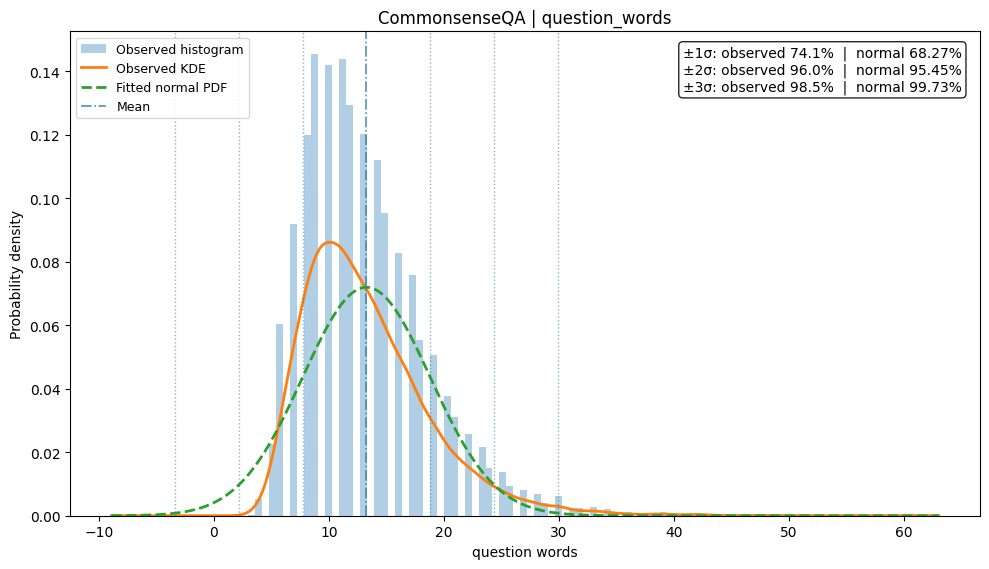

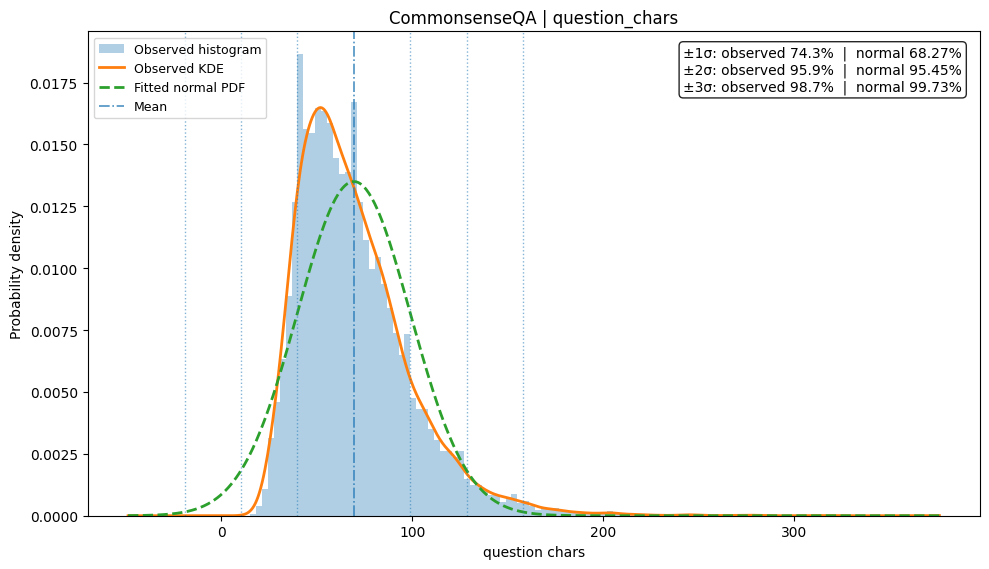

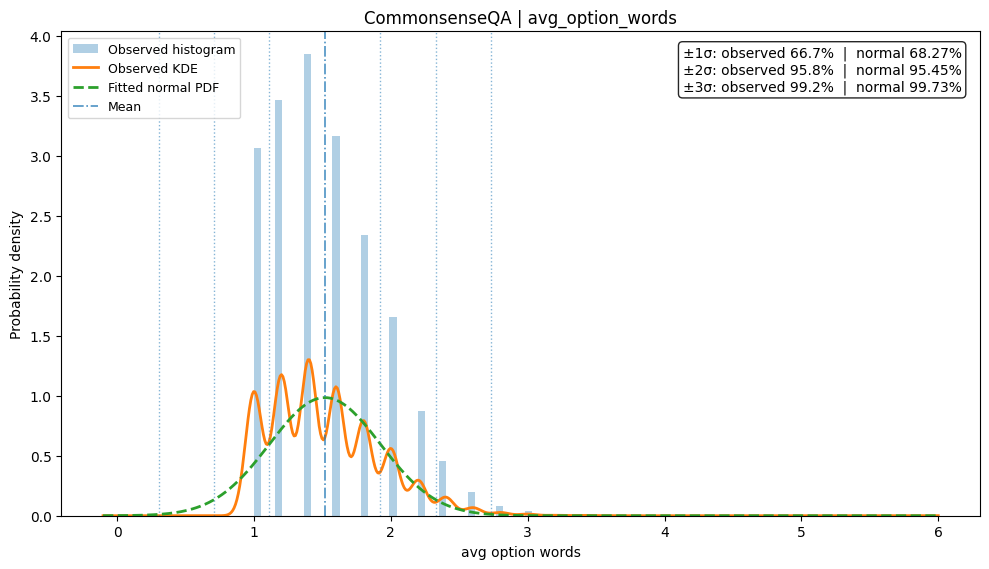

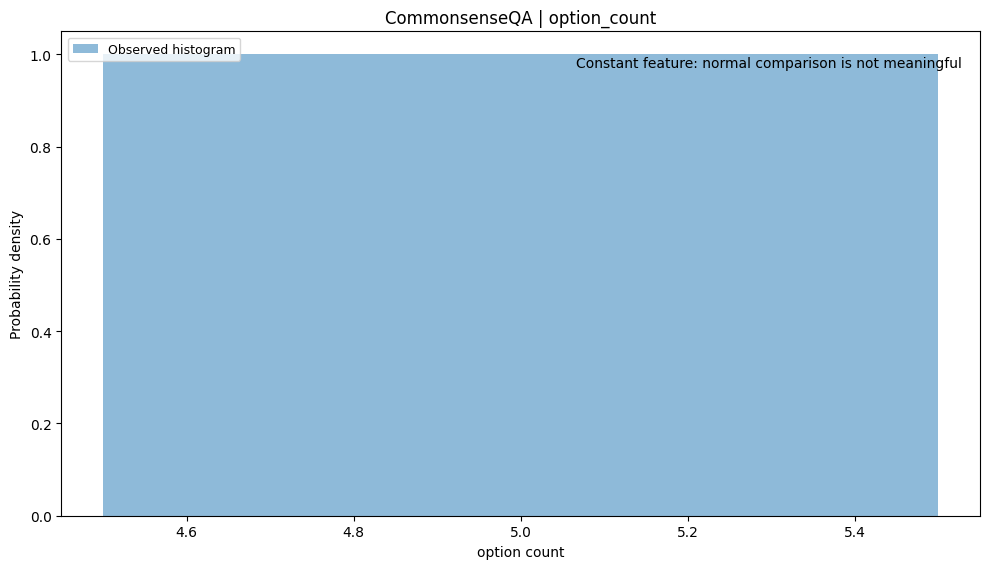

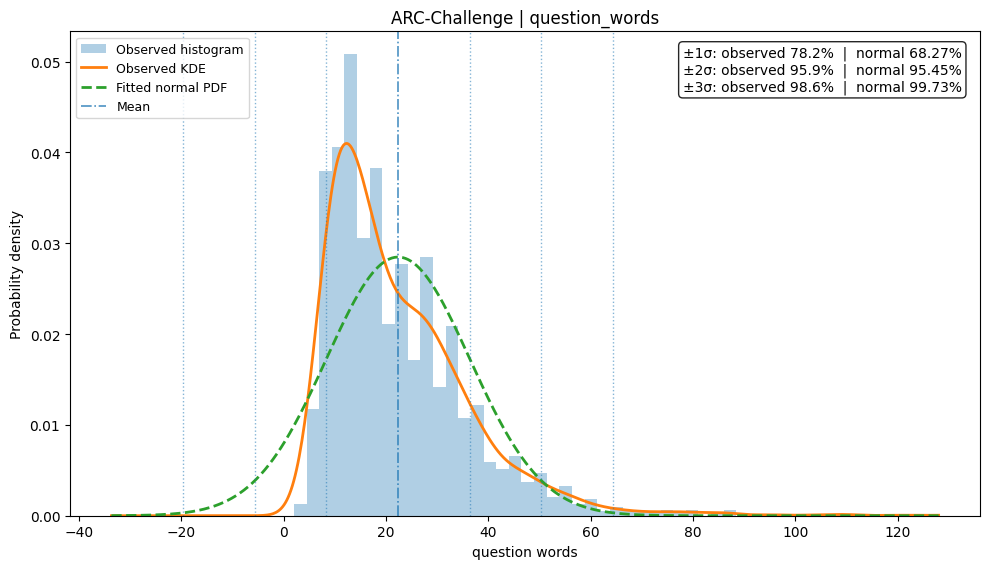

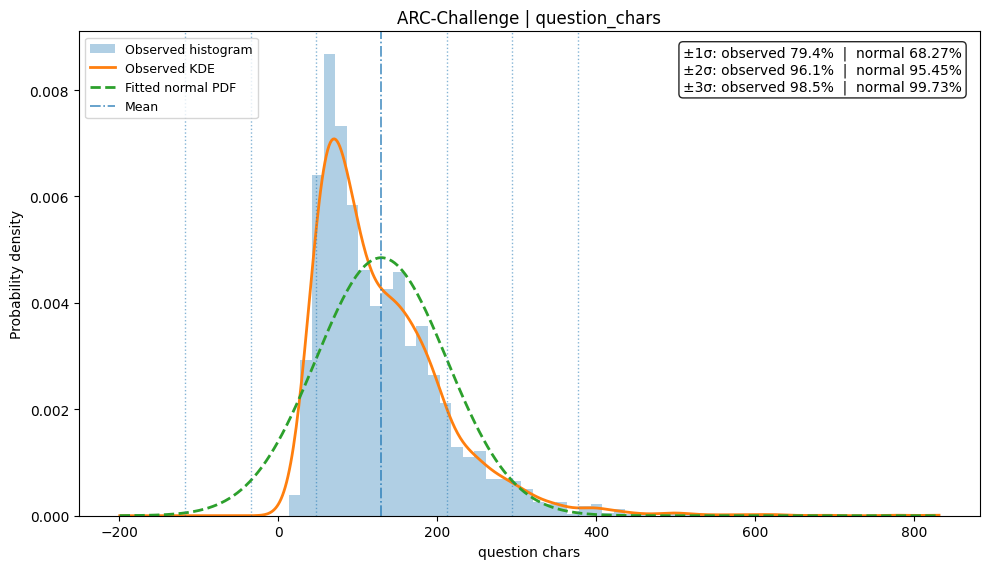

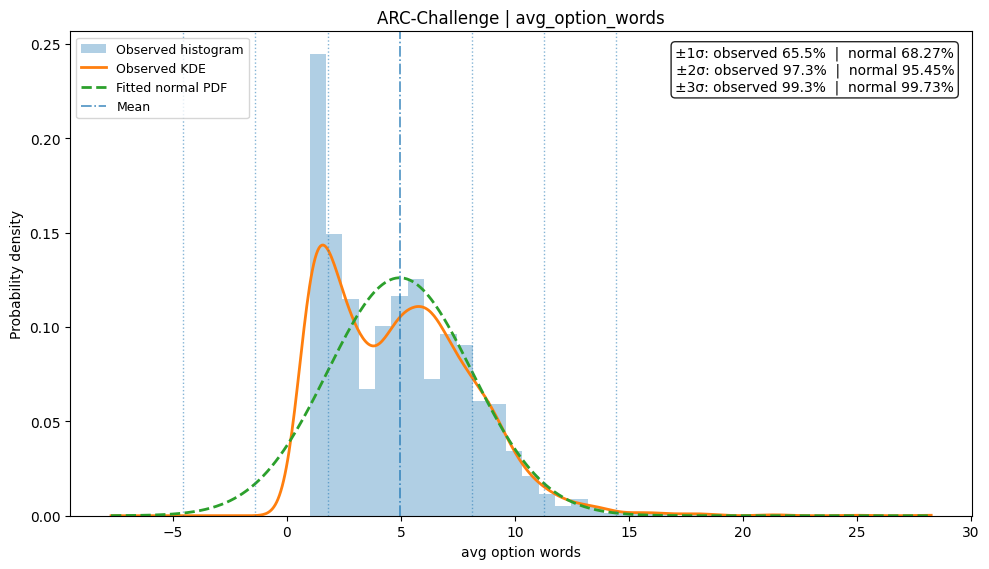

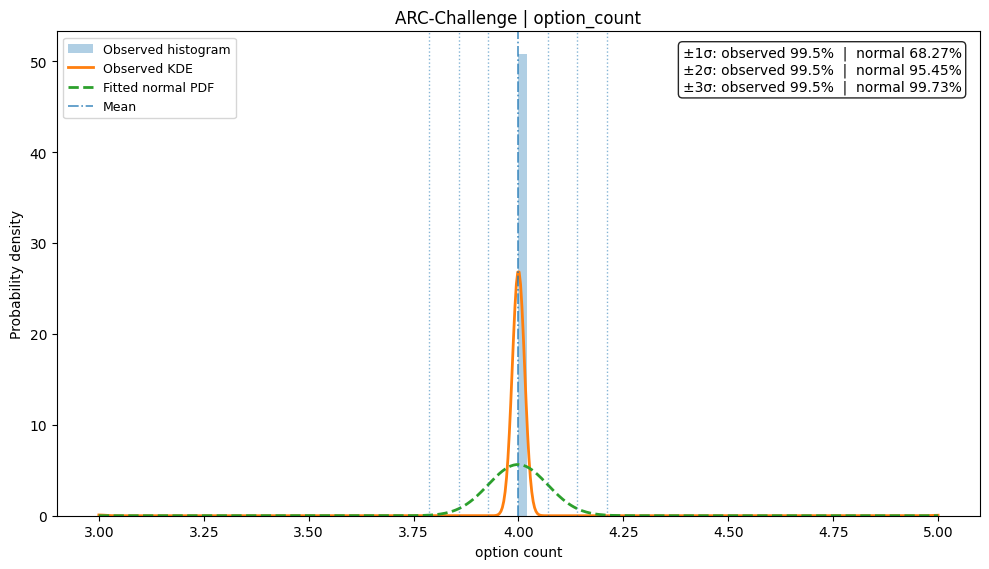

Charts saved to: D:\app\ai\Detecting Silent Failures of Uncertainty Estimators\outputs\charts


In [5]:
def plot_normal_comparison(values, dataset_name, feature_name):
    x=pd.to_numeric(pd.Series(values),errors='coerce').dropna().to_numpy(dtype=float)
    if len(x)==0:
        return
    mu=float(x.mean()); sd=float(x.std(ddof=0))
    fig,ax=plt.subplots(figsize=(10,5.8))
    if sd==0:
        ax.hist(x,bins=[mu-0.5,mu+0.5],density=True,alpha=.5,label='Observed histogram')
        ax.text(.98,.95,'Constant feature: normal comparison is not meaningful',
                transform=ax.transAxes,ha='right',va='top')
    else:
        ax.hist(x,bins='auto',density=True,alpha=.35,label='Observed histogram')
        grid=np.linspace(min(x.min(),mu-4*sd),max(x.max(),mu+4*sd),600)
        if len(np.unique(x))>2:
            try:
                kde=gaussian_kde(x)
                ax.plot(grid,kde(grid),lw=2,label='Observed KDE')
            except (np.linalg.LinAlgError,ValueError):
                pass
        ax.plot(grid,norm.pdf(grid,loc=mu,scale=sd),'--',lw=2,label='Fitted normal PDF')
        # Reference interval boundaries. The 3 ranges are nested.
        for k in (1,2,3):
            ax.axvline(mu-k*sd,ls=':',lw=1,alpha=.55)
            ax.axvline(mu+k*sd,ls=':',lw=1,alpha=.55)
        ax.axvline(mu,ls='-.',lw=1.2,alpha=.8,label='Mean')
        labels=[]
        for k,theory in NORMAL_PERCENTAGES.items():
            empirical=100*np.mean(np.abs(x-mu)<=k*sd)
            labels.append(f'±{k}σ: observed {empirical:.1f}%  |  normal {theory:.2f}%')
        ax.text(.98,.97,'\n'.join(labels),transform=ax.transAxes,
                va='top',ha='right',fontsize=10,
                bbox={'boxstyle':'round','facecolor':'white','alpha':.85})
    ax.set_title(f'{dataset_name} | {feature_name}')
    ax.set_xlabel(feature_name.replace('_',' '))
    ax.set_ylabel('Probability density')
    ax.legend(loc='upper left',fontsize=9)
    fig.tight_layout()
    filename=f"{dataset_name.lower().replace('-','_')}_{feature_name}_normal_comparison.png"
    fig.savefig(CHARTS/filename,dpi=160,bbox_inches='tight')
    plt.show();plt.close(fig)

for name,group in data.groupby('dataset',sort=False):
    for feat in FEATURES:
        plot_normal_comparison(group[feat],name,feat)
print('Charts saved to:',CHARTS)

## ۴. خروجی‌ها و نکته پژوهشی

در `outputs` جدول آمار کلی، آمار هر split، بازه‌های Q1 تا Q4، و درصدهای مقایسه قانون نرمال قرار دارند. در `outputs/charts` تصاویر نمودارها ذخیره می‌شوند.

**احتیاط:** تفاوت شکل توزیع ویژگی‌های سؤال بین دو دیتاست نشانه‌ای از تفاوت داده‌هاست، اما به‌تنهایی برای نسبت دادن شکست تخمینگر عدم‌قطعیت به Distribution Shift کافی نیست.